# PlantVillage: binary tomato leaf health CNN

This model predicts **Healthy** or **Unhealthy**, without identifying a disease name. The cells review actual saved evidence on CPU. They do not retrain the model or run more test inference.

See README.md for setup, RESULTS.md for the full report, and figures/README.md for reusable PNG/SVG captions.

In [1]:
from pathlib import Path
import json, sys
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / "model.py").exists():
    ROOT = ROOT / "cnn-plant-disease-detection"
sys.path.insert(0, str(ROOT))
OUT = ROOT / "outputs"
metrics = json.loads((OUT / "test_metrics.json").read_text())
audit = json.loads((OUT / "data_audit.json").read_text())
cv = json.loads((OUT / "cross_validation.json").read_text())
print("Dataset:", "PlantVillage")
print("Development:", audit["development_images"], "Primary test:", metrics["test_images"])
print(audit["binary_counts"])

Dataset: PlantVillage
Development: 14528 Primary test: 3632
{'Healthy': {'development': 1273, 'test': 318}, 'Unhealthy': {'development': 13255, 'test': 3314}}


## Architecture and experimental design

Both models have the same 939,874-parameter, four-block CNN and two-output head. RGB inputs are resized to 128×128 and normalized to [-1,1]. Validation uses five groups of development images; the final fit uses twenty epochs and fixed argmax decisions.

PlantVillage estimates a fixed scratch recipe. Bangladesh compares scratch and PlantVillage feature adaptation using development-only balanced accuracy. Test scores do not select recipes or thresholds.

TomatoCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilat

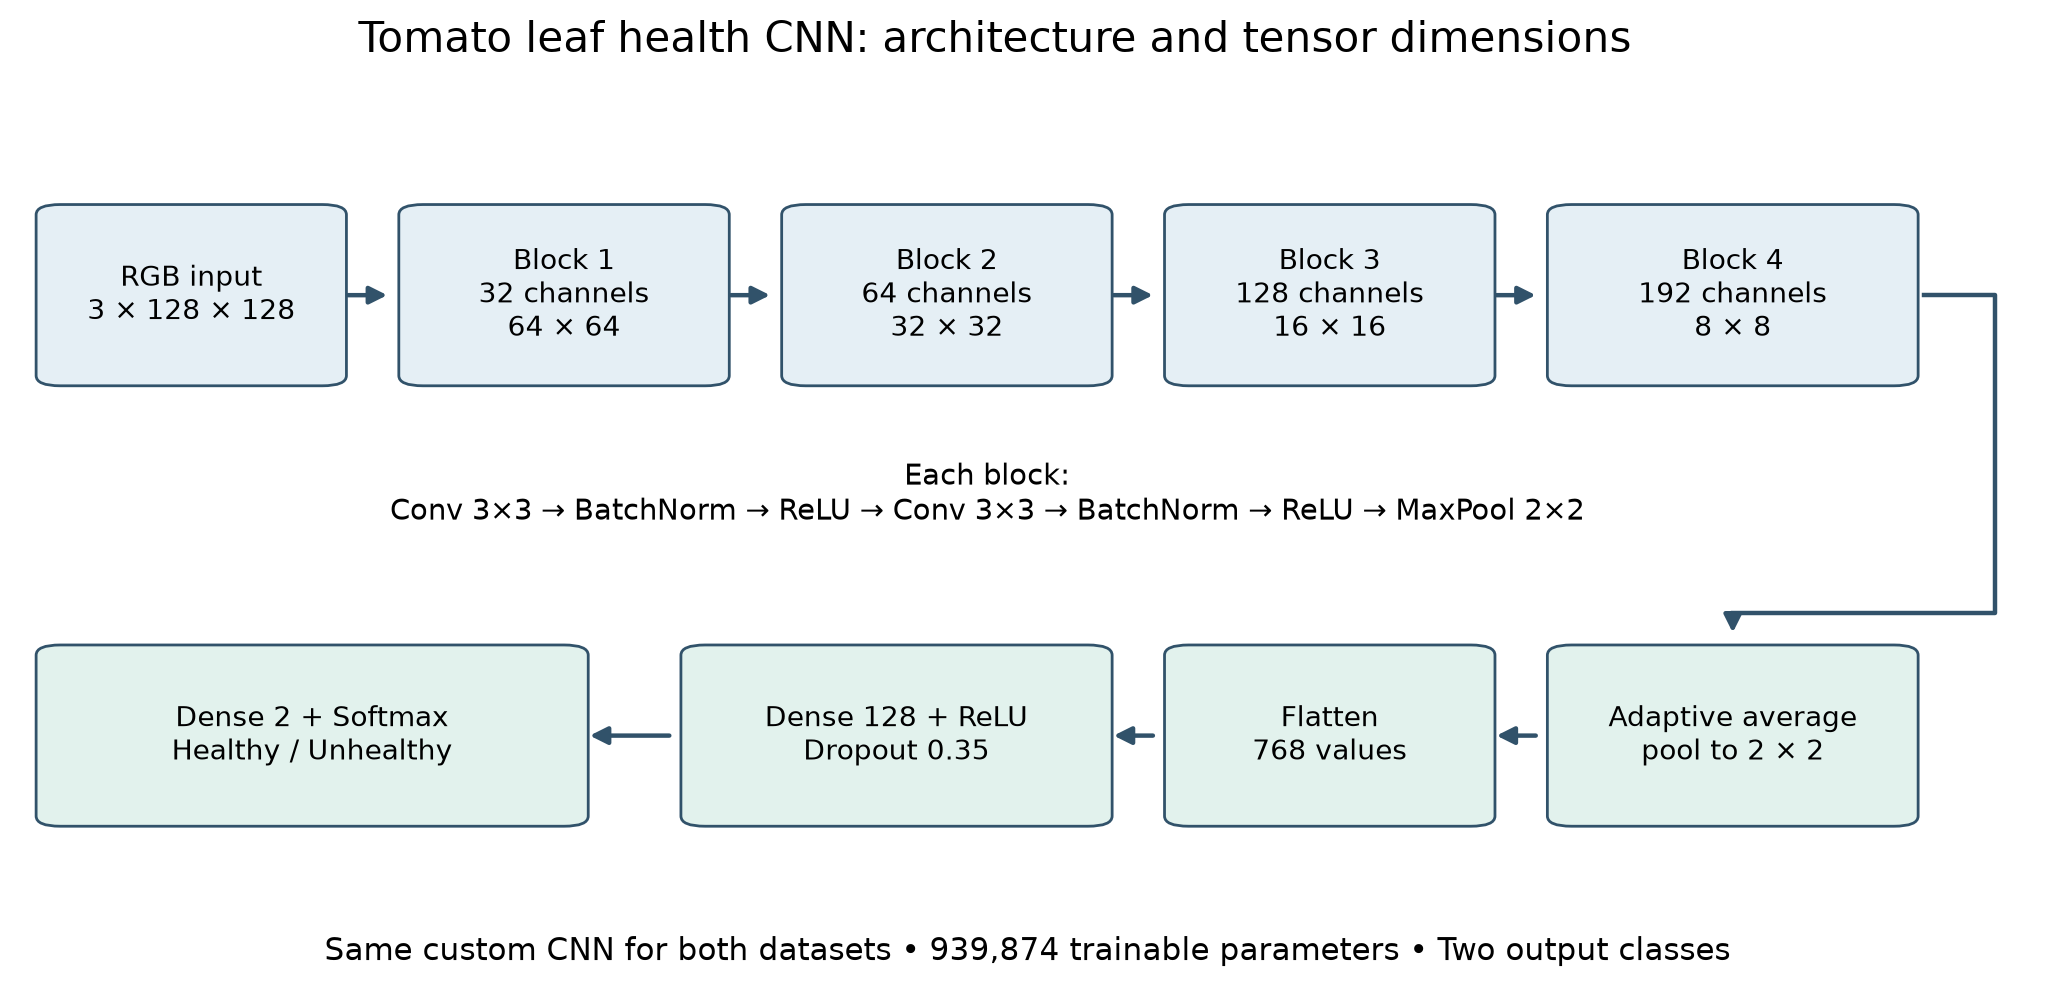

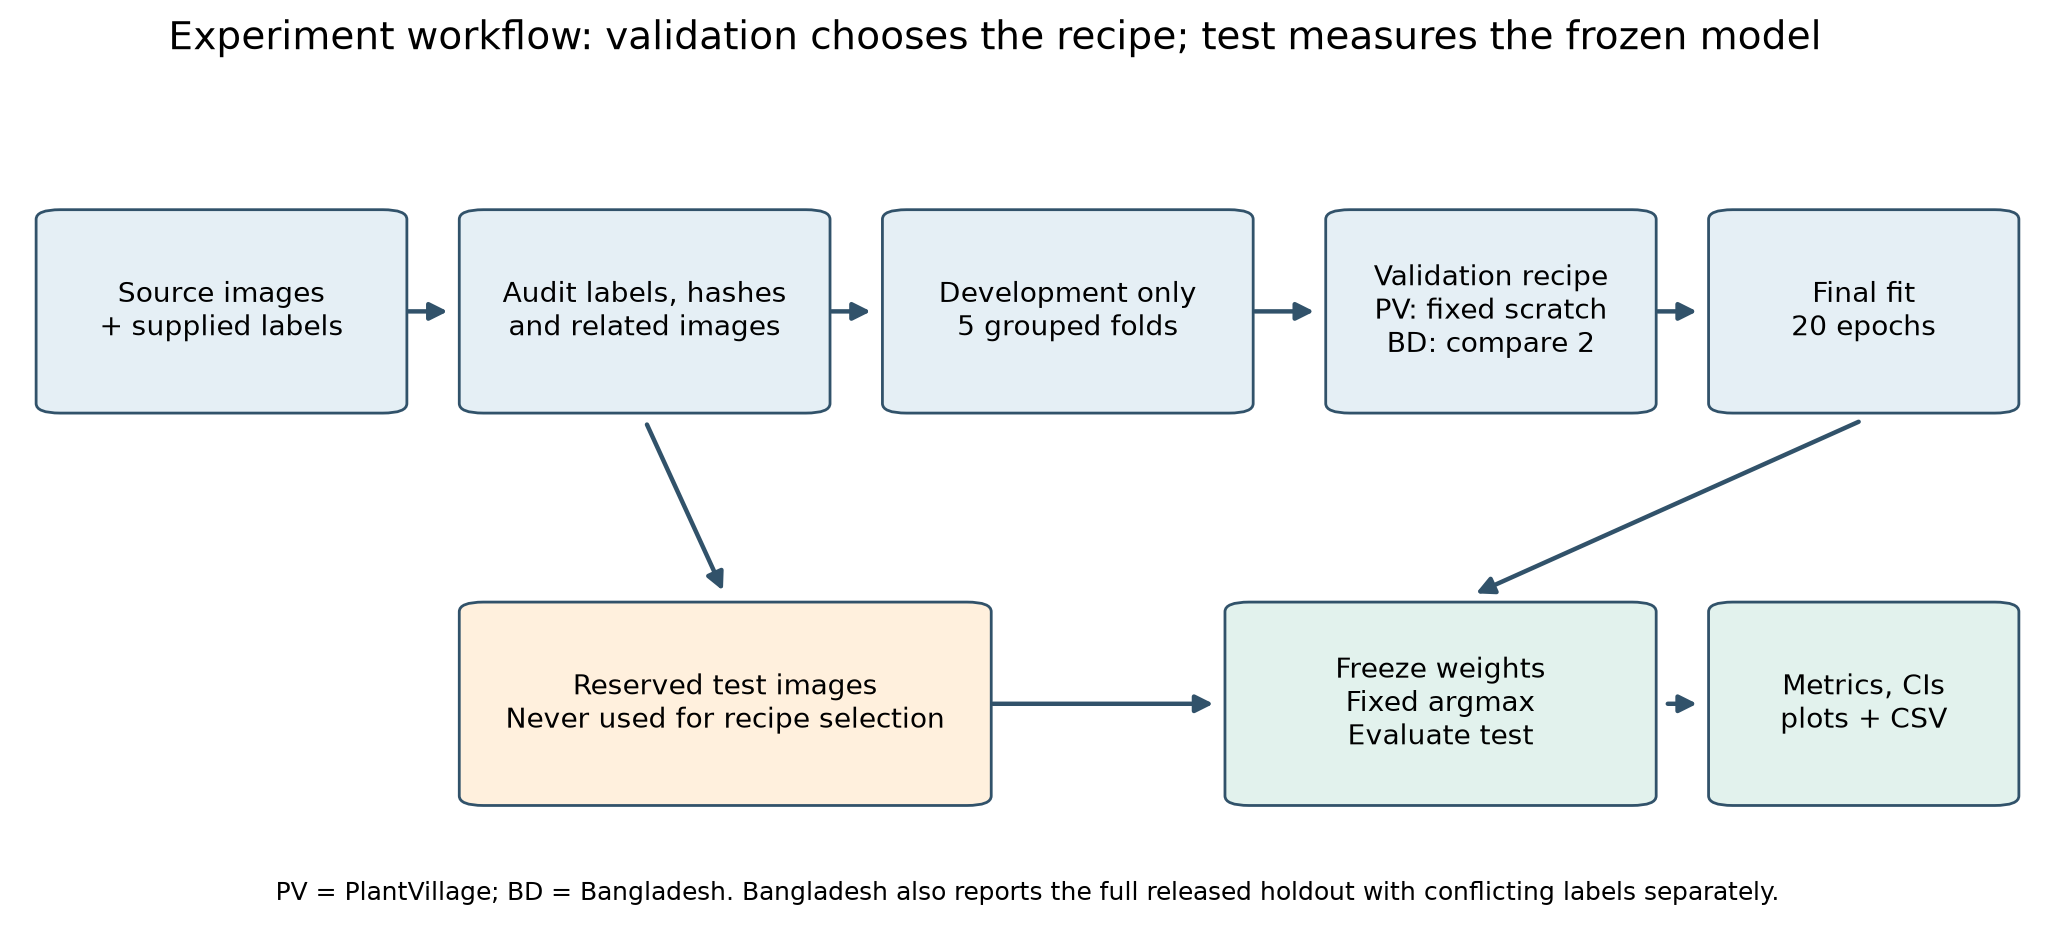

In [2]:
import torch
from model import TomatoCNN
checkpoint = torch.load(OUT / "tomato_cnn.pt", map_location="cpu", weights_only=True)
model = TomatoCNN(checkpoint["channels"], 2)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Classes:", checkpoint["classes"])
display(Image(filename=str(ROOT / "figures/cnn_architecture.png"), width=1000))
display(Image(filename=str(ROOT / "figures/experiment_workflow.png"), width=1000))

scratch CV balanced accuracy: 99.26% CV macro F1: 97.69%


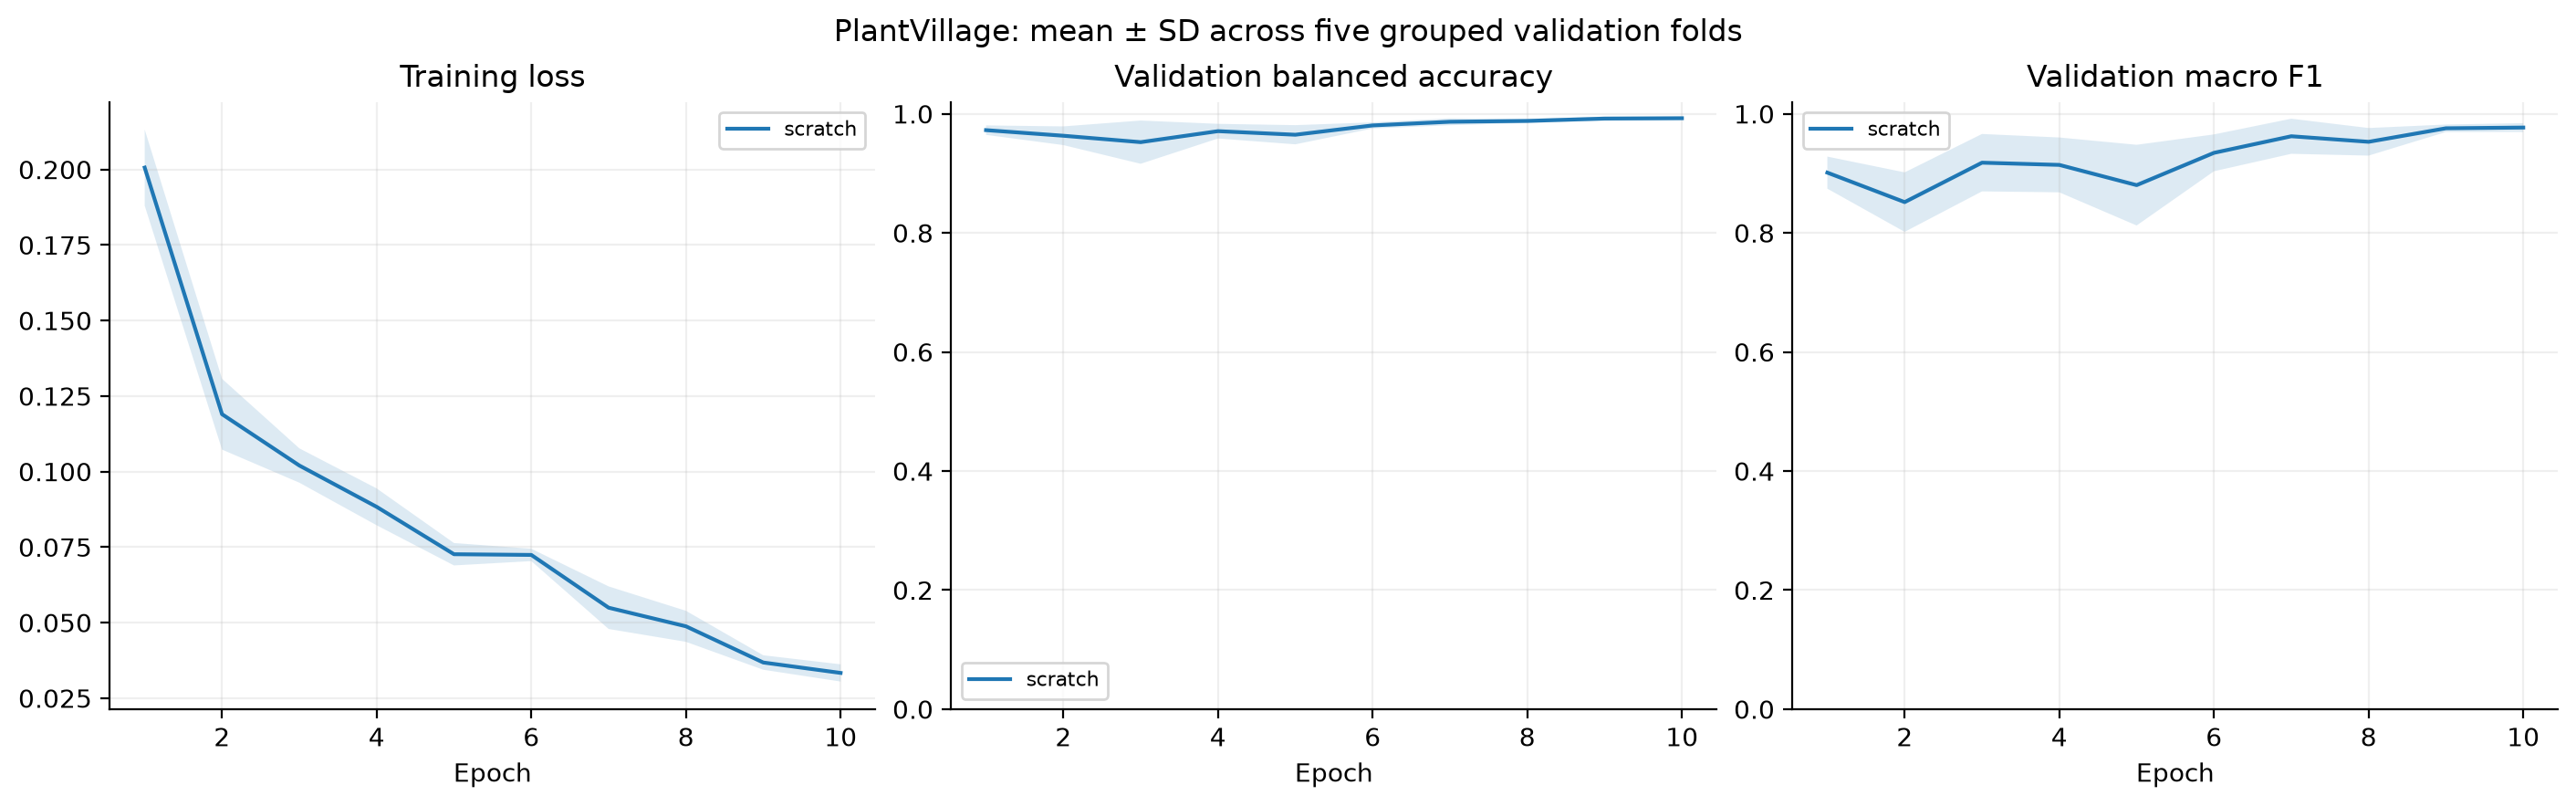

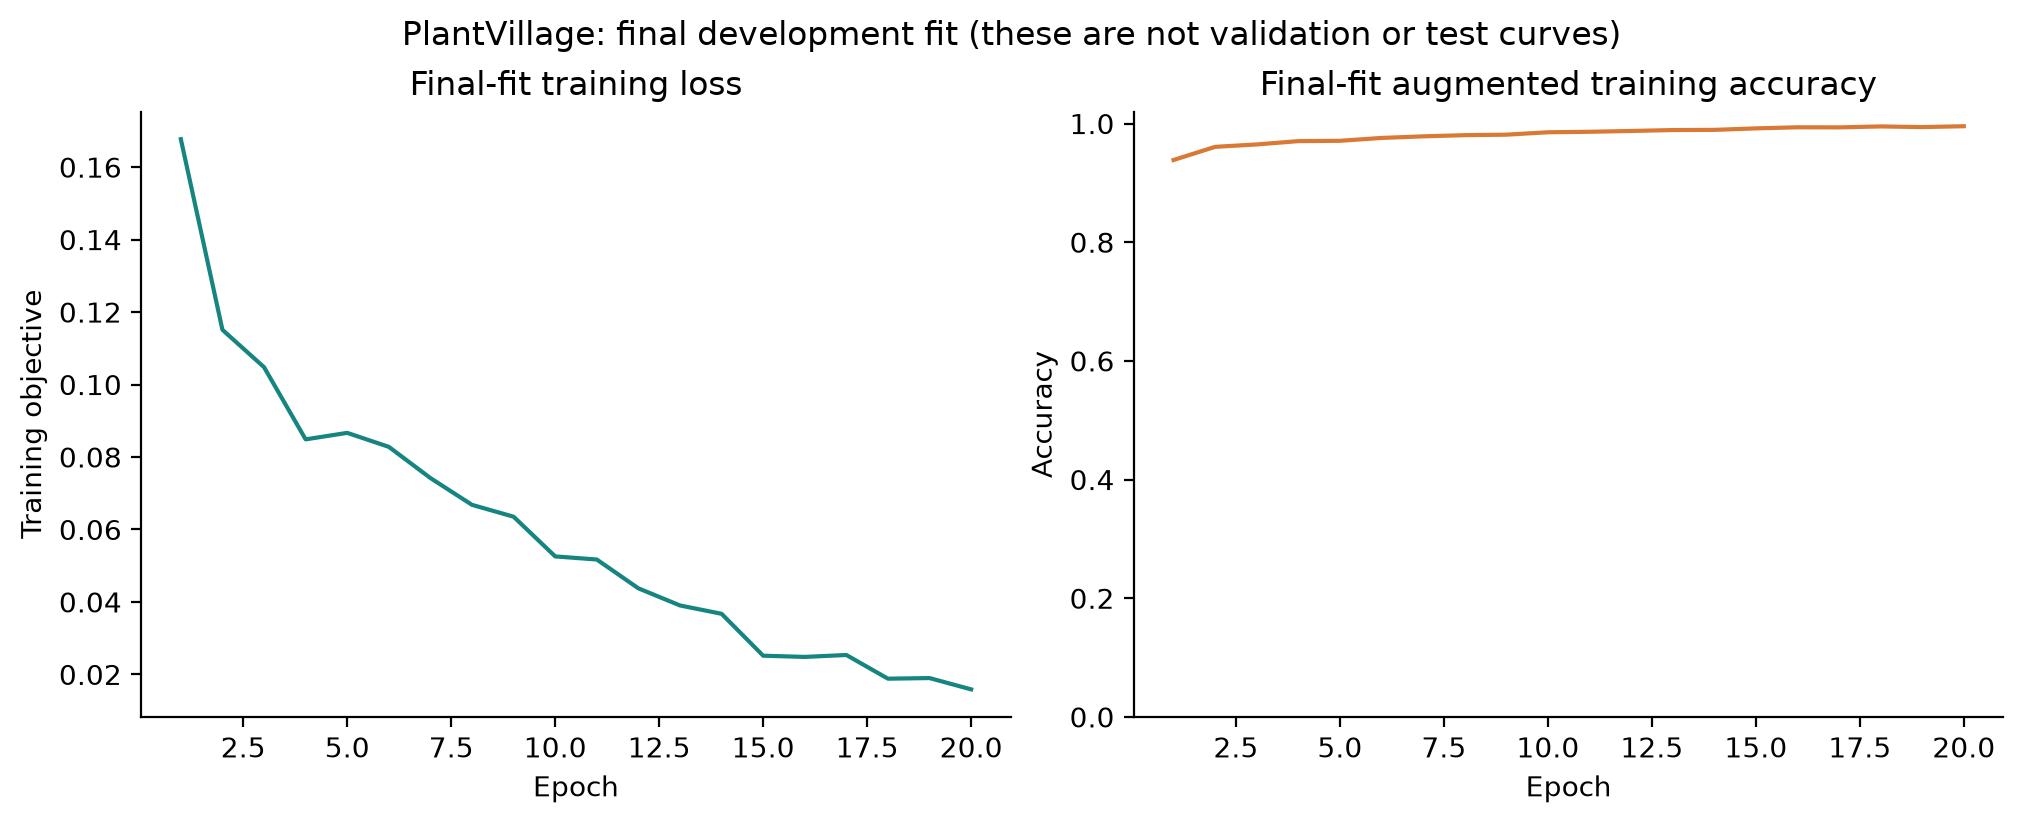

In [3]:
for mode, scores in cv.items():
    print(mode, "CV balanced accuracy:", f"{scores["mean_balanced_accuracy"]:.2%}", "CV macro F1:", f"{scores["mean_macro_f1"]:.2%}")
display(Image(filename=str(ROOT / "figures/plantvillage_cv_learning_curves.png"), width=1000))
display(Image(filename=str(ROOT / "figures/plantvillage_final_training_curves.png"), width=1000))

## Primary test

Accuracy is shown alongside balanced accuracy and macro F1. Healthy recall is specificity with Unhealthy as the positive class. A high own-dataset score does not establish performance on new gardens. Bangladesh's primary cohort contains only predefined eligible images whose supplied labels agree.

accuracy 99.86%
balanced_accuracy 99.92%
macro_f1 99.57%
specificity_healthy 100.00%
recall_sensitivity_unhealthy 99.85%
precision_unhealthy 100.00%
f1_unhealthy 99.92%
Reference rows / prediction columns: [[318, 0], [5, 3309]]


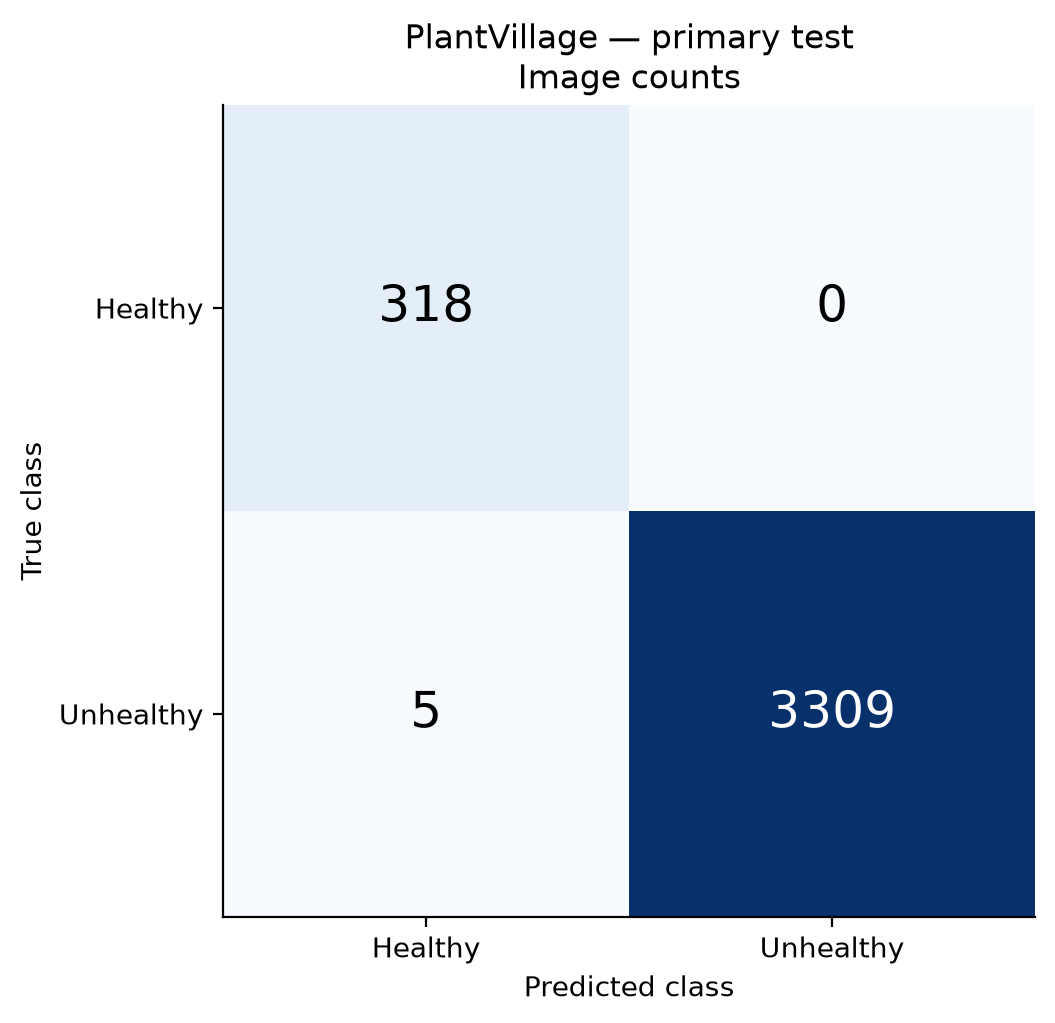

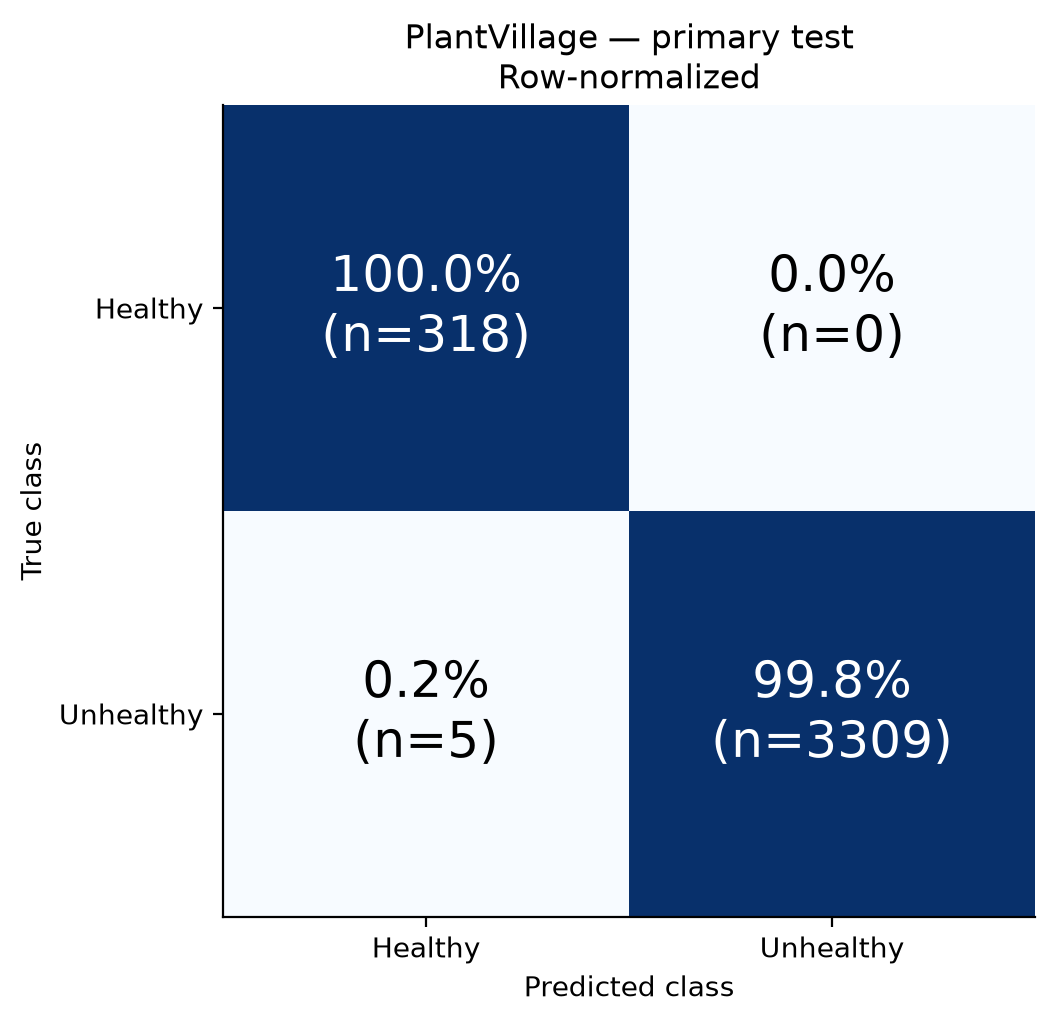

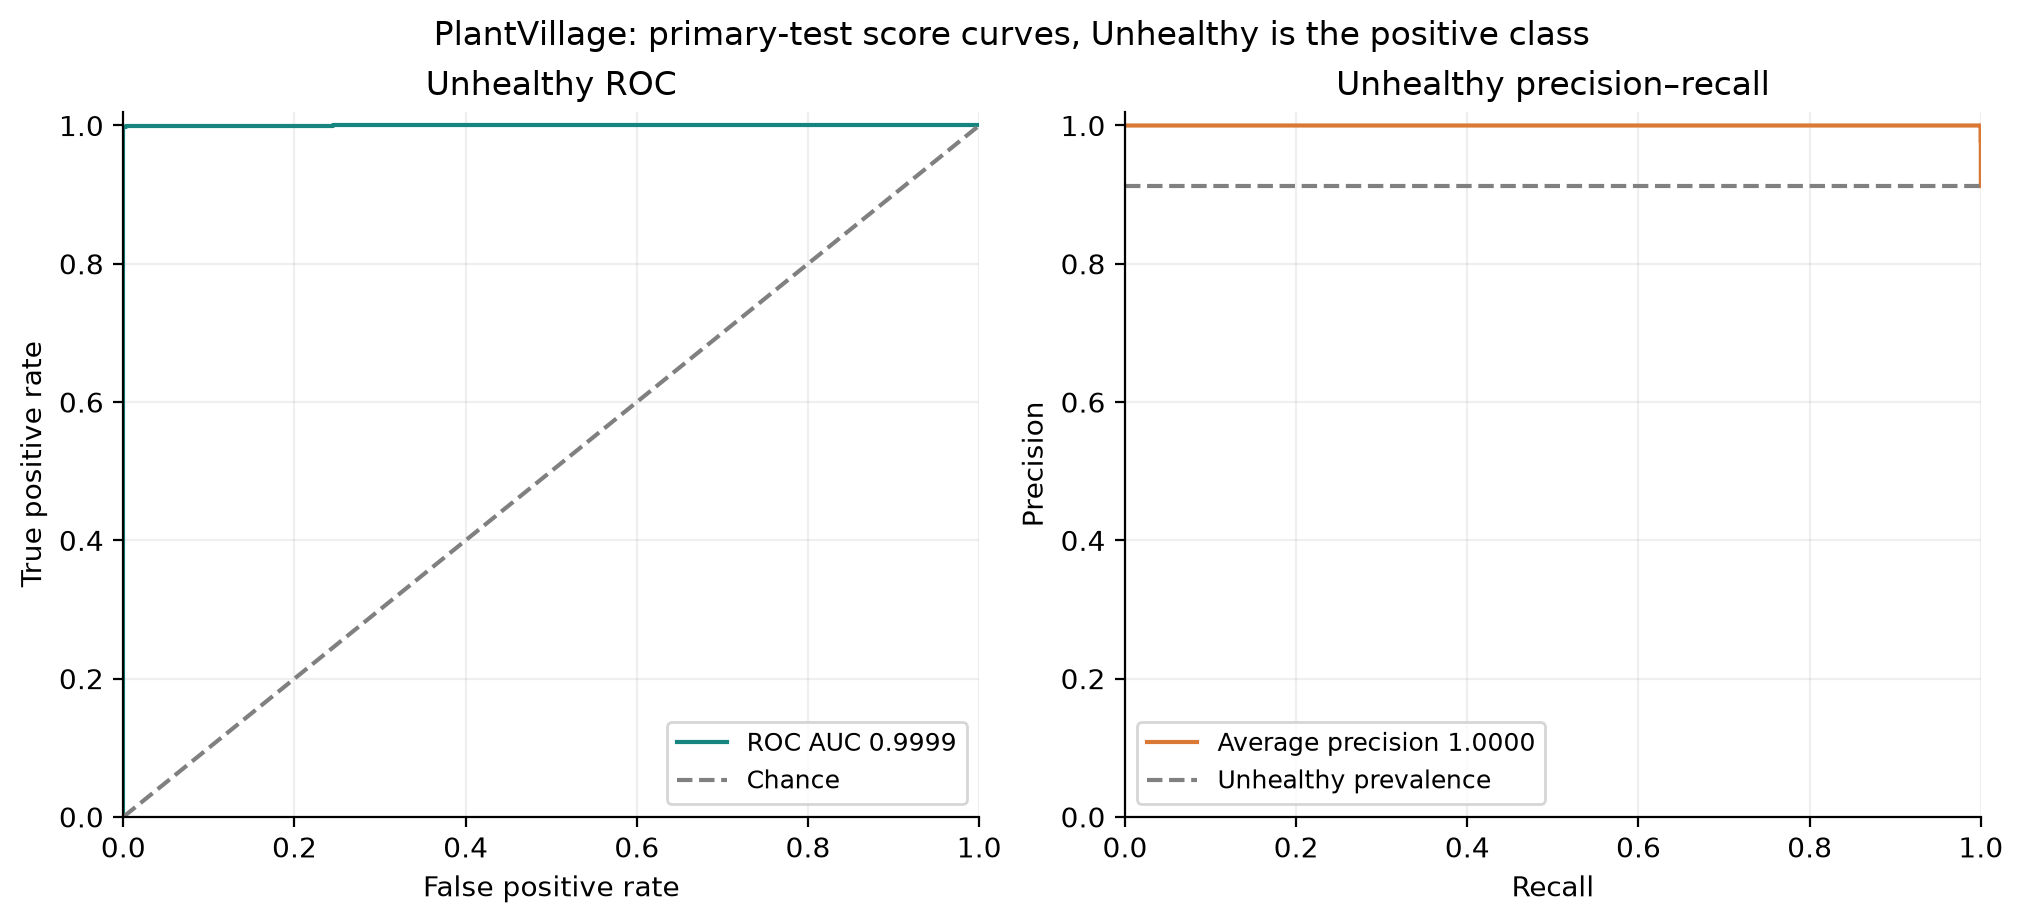

In [4]:
for key in ("accuracy", "balanced_accuracy", "macro_f1", "specificity_healthy", "recall_sensitivity_unhealthy", "precision_unhealthy", "f1_unhealthy"):
    print(key, f"{metrics[key]:.2%}")
print("Reference rows / prediction columns:", metrics["confusion_matrix"])
display(Image(filename=str(ROOT / "figures/plantvillage_confusion_counts.png"), width=650))
display(Image(filename=str(ROOT / "figures/plantvillage_confusion_normalized.png"), width=650))
display(Image(filename=str(ROOT / "figures/plantvillage_roc_precision_recall.png"), width=1000))

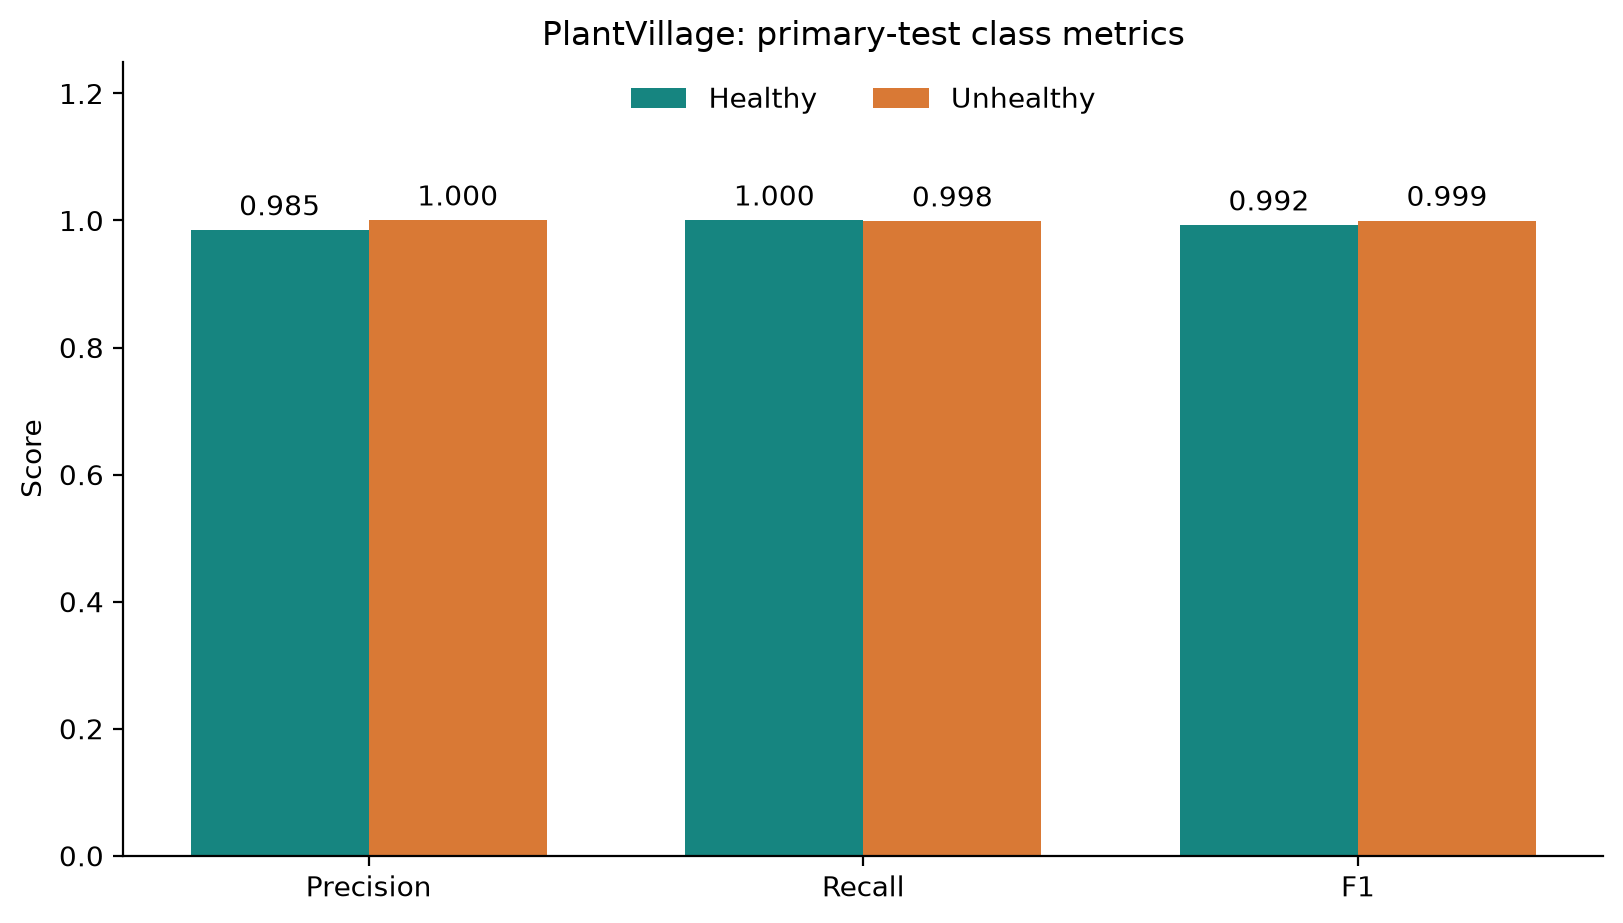

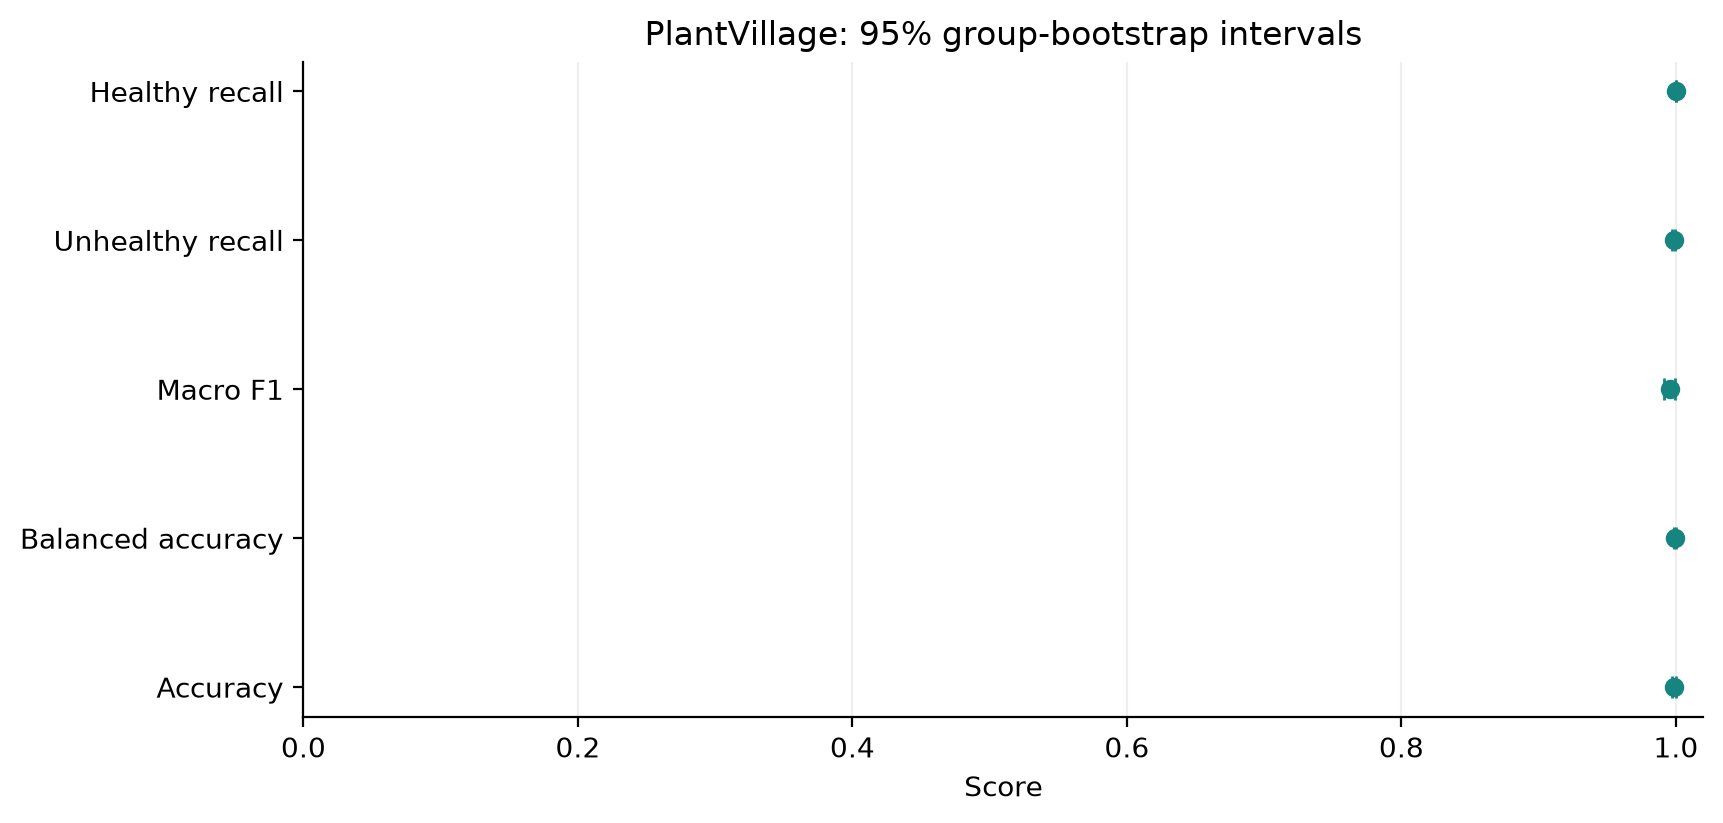

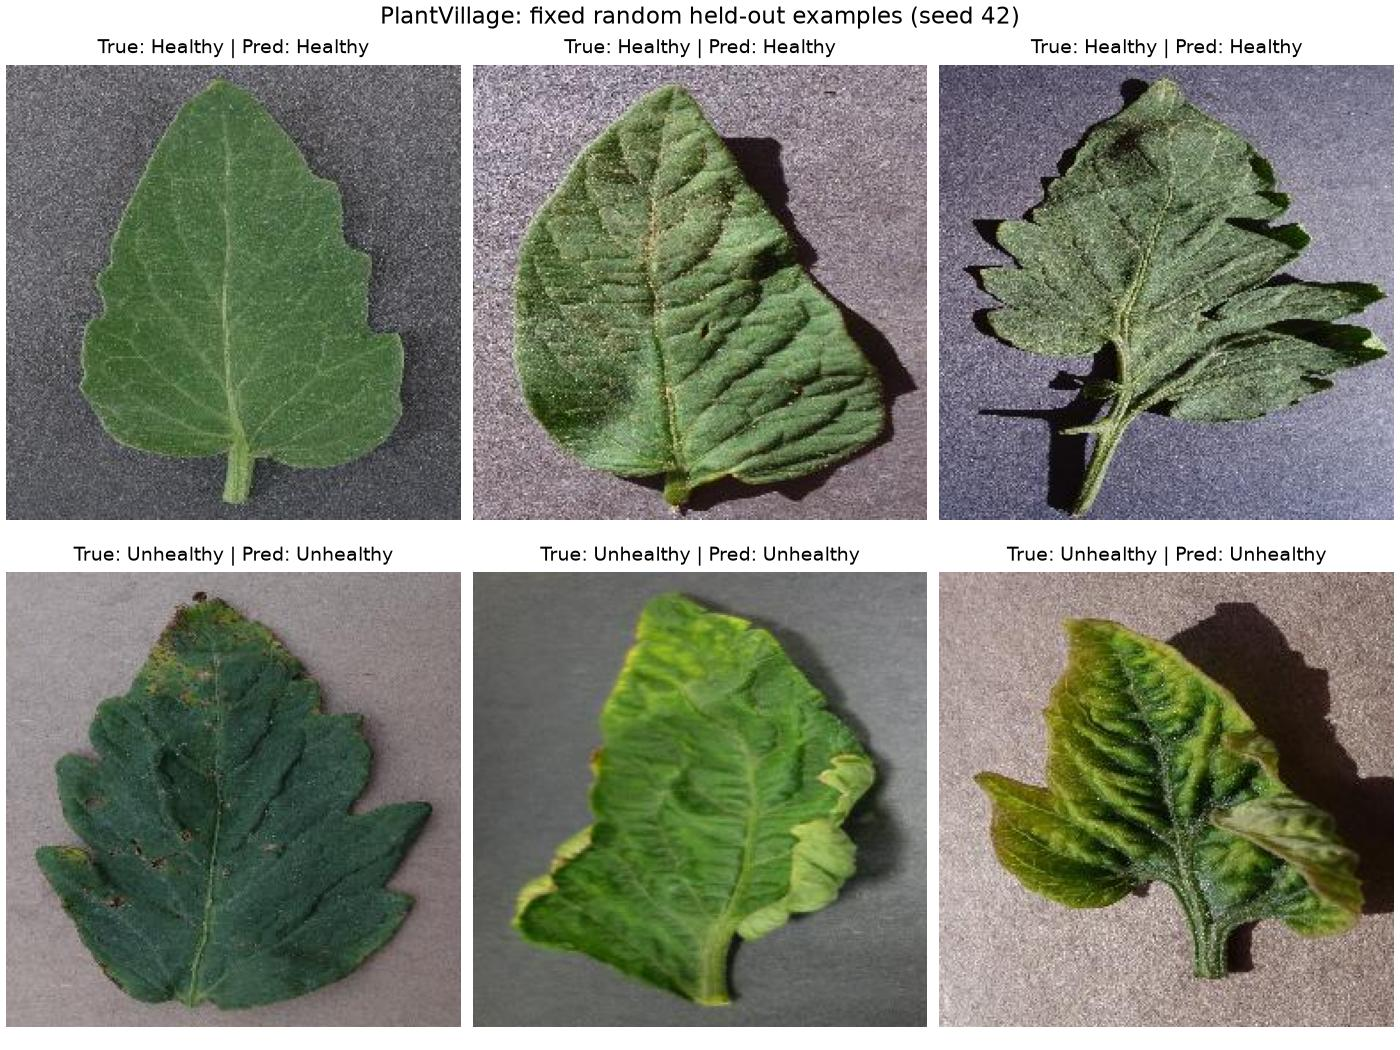

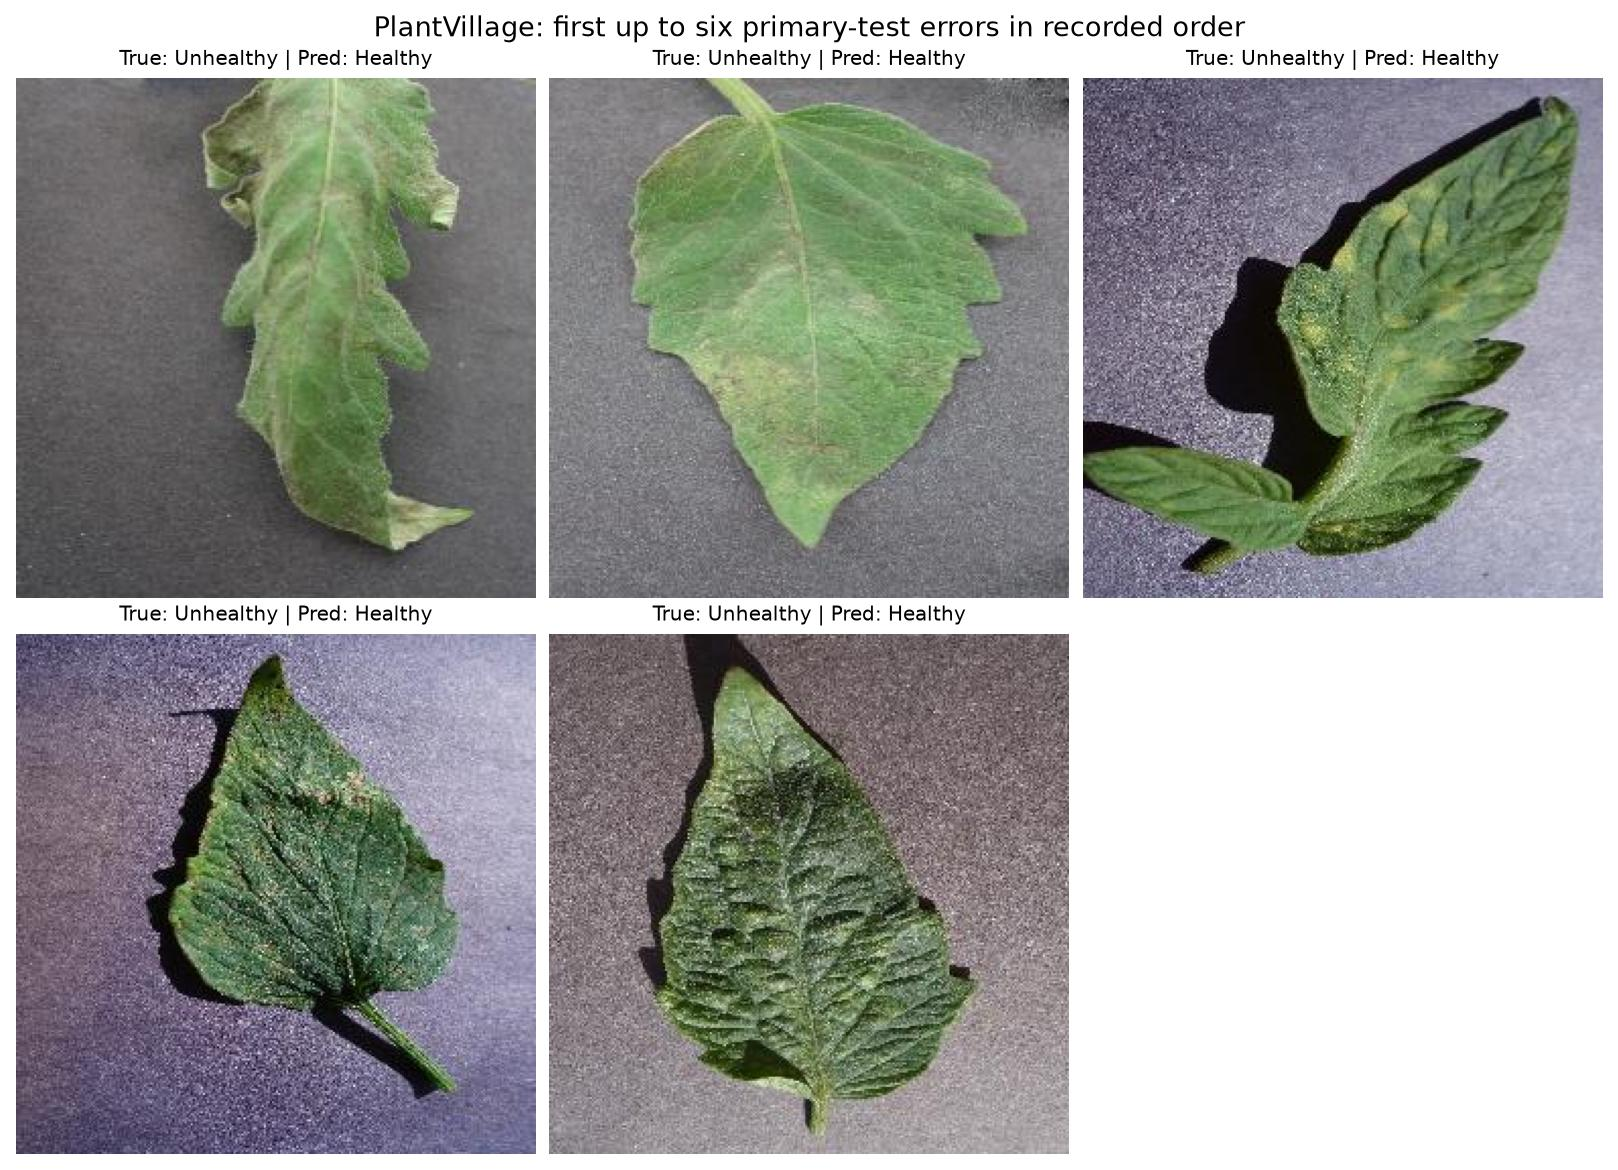

In [5]:
display(Image(filename=str(ROOT / "figures/plantvillage_class_metrics.png"), width=900))
display(Image(filename=str(ROOT / "figures/plantvillage_confidence_intervals.png"), width=900))
display(Image(filename=str(ROOT / "figures/plantvillage_test_examples.jpg"), width=900))
error_gallery = ROOT / "figures/plantvillage_errors.jpg"
if error_gallery.exists():
    display(Image(filename=str(error_gallery), width=900))

## Try a photograph

```powershell
python predict.py "C:\path\to\leaf.jpg" --dataset plantvillage
```

See CNN_GUIDE.md for the metric definitions and DATA_SOURCES.md for source/label limitations.

In [6]:
print(json.loads((OUT / "verification.json").read_text()))
report = (OUT / "REPORT.md").read_text(encoding="utf-8").replace("](../", "](")
display(Markdown(report))

{'passed': True, 'dataset': 'plantvillage', 'binary_checkpoint_loaded_on_cpu': True, 'checkpoint_sha256': '180745a16069f20309bb2945a3c24d3977678e667a86ac6f30d5db8f1e8dedbf', 'test_csv_confusion_metrics_independently_verified': True, 'all_class_precision_recall_f1_verified': True, 'split_and_cv_groups_pixels_files_disjoint': True, 'cv_summaries_and_history_lengths_checked': True, 'test_inference_performed': False}


# PlantVillage: binary results

See ../README.md for setup, ../DATA_SOURCES.md for provenance, and ../RESULTS.md for the combined report.

## PlantVillage

The primary test recognized **318 / 318 Healthy** and **3309 / 3314 Unhealthy** leaves.

| Metric | Value |
|---|---:|
| Accuracy | 99.86% |
| Balanced accuracy | 99.92% |
| Macro F1 | 99.57% |
| Weighted F1 | 99.86% |
| Unhealthy precision | 100.00% |
| Unhealthy recall | 99.85% |
| Healthy recall | 100.00% |
| Unhealthy F1 | 99.92% |
| Healthy precision | 98.45% |
| Healthy F1 | 99.22% |
| ROC AUC | 0.9999 |
| Average precision | 1.0000 |

![Confusion counts](figures/plantvillage_confusion_counts.png)

![Row-normalized confusion matrix](figures/plantvillage_confusion_normalized.png)

![Grouped validation learning curves](figures/plantvillage_cv_learning_curves.png)

![Final-fit training curves](figures/plantvillage_final_training_curves.png)

![ROC and precision–recall](figures/plantvillage_roc_precision_recall.png)

![Per-class precision, recall, F1](figures/plantvillage_class_metrics.png)

![Group-bootstrap uncertainty](figures/plantvillage_confidence_intervals.png)

![Actual learned first-layer filters](figures/plantvillage_first_layer_filters.png)

![Fixed random test examples](figures/plantvillage_test_examples.jpg)

![Recorded test errors](figures/plantvillage_errors.jpg)

